# MEMC exercise 2 – The insurance company

---

The first "real" problem of the course: an insurance company collects premiums, pays out claims
during the year, and we want to know the **probability of ruin** (the claims exceed what it has
available).

In this notebook you see:

- how to turn a description of reality into a simulation model
- what a "pen and paper" estimate via the CLT looks like
- why simulation is the better tool for this problem: **with the CLT approximation we do not know
  how accurate it is, with the simulation we do**

Only half of the problem fits in here. The tools it needs (inverse transform, geometric gaps,
ordered samples, variance reduction) are what we learn in exercises 3 to 7. In **exercise 9** we
come back to the insurance company and finish it properly: confidence intervals, rare ruins, and the
question "how much capital do we need?".

In [1]:
import math
import random
import time

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def estimate(sampler, n):
    '''Plain Monte Carlo: the average of n calls of the generator and its standard error sigma/sqrt(n).'''
    s = s2 = 0.0
    for _ in range(n):
        x = sampler()
        s += x
        s2 += x * x
    mean = s / n
    var = max(s2 / n - mean * mean, 0.0)
    return mean, math.sqrt(var / n)


def check(name, mean, se, exact, k=5):
    '''Prints the estimate and verifies it lies within k standard errors of the exact value.'''
    print(f"{name}: {spaces(mean, ',.5g')} +- {spaces(se, ',.2g')}  (exact {spaces(exact, ',.5g')})")
    assert abs(mean - exact) <= k * se, name


def Phi(x):
    '''Distribution function of N(0, 1).'''
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))

def spaces(x, spec=","):
    '''A number with spaces instead of commas as the thousands separator.'''
    return format(x, spec).replace(",", " ")

## 1. The model

We turn the description of reality into a model with a few assumptions:

1. We divide the year into $N$ equal intervals (days, say) that are small enough that **at most one**
   claim occurs in any one of them.
2. In each interval there is a claim with probability $p$, independently of the others (a Bernoulli
   trial).
3. The size of a single claim is $X = L\cdot R$, where $L$ is the maximum payout and the relative
   size $R \in [0, 1]$ has **density $2r$**, i.e. the distribution function $F(r) = r^2$. The density
   increases, so large claims are more common than small ones, and the expectation is $E R = 2/3$.
4. The company has capital $K$ available (the initial capital plus the premiums collected). Ruin
   occurs when the payouts exceed this capital.

We build the generator for $R$ by the **inverse transform method** (exercise 4): from $F(r) = r^2$ we
get $F^{-1}(\gamma) = \sqrt{\gamma}$, so $R = \sqrt{\gamma}$ with $\gamma \sim R(0,1)$.

**A handy observation:** payouts only accumulate, so ruin at some point during the year happens
**exactly when the total annual payout $T$ exceeds $K$**. So it is enough to simulate $T$; we do not
have to track the course of the year.

The two sets of parameters we will work with:

| | $N$ | $p$ | $L$ | $K$ | Character |
|---|-----|-----|-----|-----|-----------|
| Scenario A | 365 | 0.05 | 10 000 | 200 000 | ruin is **rare** |
| Scenario B | 1000 | 0.15 | 100 000 | 10 000 000 | ruin in about half the cases |

In [2]:
SCENARIO_A = dict(N=365, p=0.05, L=10_000, K=200_000)
SCENARIO_B = dict(N=1000, p=0.15, L=100_000, K=10_000_000)


def claim(L):
    '''The size of one claim: L * R, where R has density 2r on [0, 1] (inverse transform: R = sqrt(γ)).'''
    return L * math.sqrt(random.random())


def annual_payout_slow(N, p, L):
    '''The literal simulation: we walk through all N intervals and toss a coin with probability p in each.'''
    T = 0.0
    for _ in range(N):
        if random.random() < p:
            T += claim(L)
    return T

What the model looks like: on the left the distribution of **a single claim** (the density $2r$ and
a histogram of generated $R = \sqrt{\gamma}$), on the right **several simulated years** in scenario
A. Every step is one claim, the curve is the cumulative payout, and the company goes bust the moment
it crosses the capital $K$ (the horizontal line). In scenario A crossing $K$ is rare, which is why
most of the curves never reach the line at all.

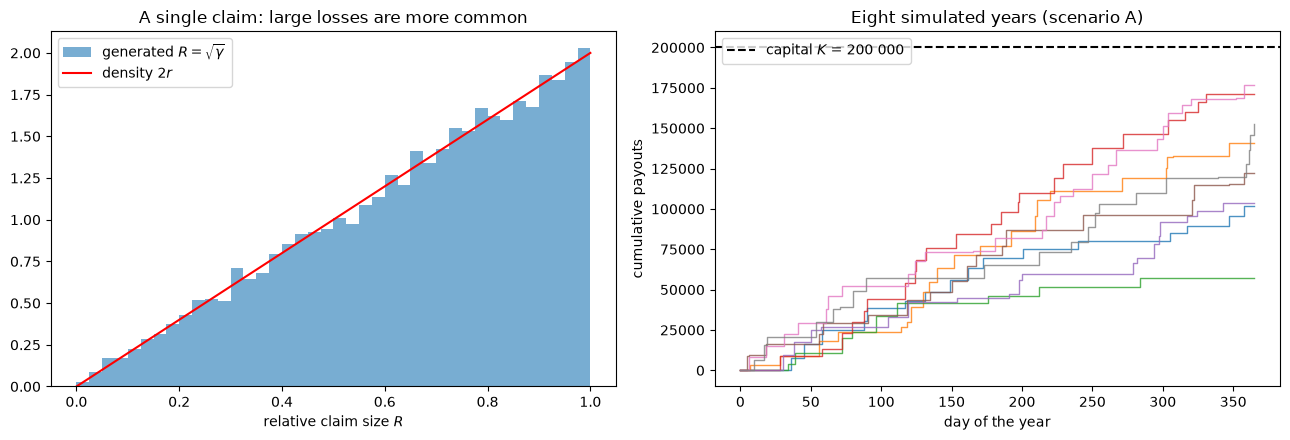

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# left: the relative claim size R = sqrt(γ) and the density 2r
Rs = [math.sqrt(random.random()) for _ in range(20_000)]
axes[0].hist(Rs, bins=40, range=(0, 1), density=True, alpha=0.6, label="generated $R = \\sqrt{\\gamma}$")
axes[0].plot([0, 1], [0, 2], "r", label="density $2r$")
axes[0].set_xlabel("relative claim size $R$")
axes[0].set_title("A single claim: large losses are more common")
axes[0].legend()

# right: cumulative payouts during the year, scenario A
sc = SCENARIO_A
ax = axes[1]
for run in range(8):
    t_, cum, s = [0], [0.0], 0.0
    for day in range(1, sc["N"] + 1):
        if random.random() < sc["p"]:
            s += claim(sc["L"])
        t_.append(day)
        cum.append(s)
    ax.step(t_, cum, where="post", lw=1, alpha=0.8)
ax.axhline(sc["K"], color="k", ls="--", label=f"capital $K$ = {spaces(sc['K'])}")
ax.set_xlabel("day of the year")
ax.set_ylabel("cumulative payouts")
ax.set_title("Eight simulated years (scenario A)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 2. An approximate solution via the CLT

The annual payout $T$ is the sum of $N$ independent, identically distributed variables $Y_i$
($Y_i = X$ with probability $p$, otherwise $0$). Writing $\mu = E X$ and $\sigma^2 = D X$,

$$E T = N p\mu, \qquad D T = N\big(p\sigma^2 + \mu^2 p(1-p)\big) = N\big(p\,E X^2 - p^2\mu^2\big).$$

By the CLT, $T$ is approximately normal and

$$p_u = P(T > K) \approx 1 - \Phi\!\left(\frac{K - E T}{\sqrt{D T}}\right).$$

For our model $\mu = 2L/3$ and $E X^2 = L^2/2$. How good an approximation this is, is **hard to
judge** (we do not know how large the CLT's error is for our $N$). The simulation does not have this
problem.

In [4]:
def theory(N, p, L, K):
    mu = 2 * L / 3
    EX2 = L * L / 2
    ET = N * p * mu
    VarT = N * (p * EX2 - (p * mu) ** 2)
    p_clt = 1 - Phi((K - ET) / math.sqrt(VarT))
    return ET, VarT, p_clt


for name, sc in (("A", SCENARIO_A), ("B", SCENARIO_B)):
    ET, VarT, p_clt = theory(**sc)
    print(f"Scenario {name}: E T = {spaces(ET, ',.0f')},  std. deviation of T = {spaces(math.sqrt(VarT), ',.0f')},  K = {spaces(sc['K'])},  "
          f"p_u (CLT) = {p_clt:.4f}")

Scenario A: E T = 121 667,  std. deviation of T = 29 529,  K = 200 000,  p_u (CLT) = 0.0040
Scenario B: E T = 10 000 000,  std. deviation of T = 806 226,  K = 10 000 000,  p_u (CLT) = 0.5000


## 3. The simulation

The literal simulation (one iteration per interval) is slow, but it corresponds directly to the
model. First we verify that it generates the right annual payouts: the expectation and the variance
have to match the formulas above.

In [5]:
sc = SCENARIO_A
ET, VarT, _ = theory(**sc)

n = 20_000
t0 = time.perf_counter()
m, se = estimate(lambda: annual_payout_slow(sc["N"], sc["p"], sc["L"]), n)
t_slow = (time.perf_counter() - t0) / n
check("E T", m, se, ET)
print(f"std. deviation of T: simulation {spaces(se * math.sqrt(n), ',.0f')}, formula {spaces(math.sqrt(VarT), ',.0f')}")
print(f"time for one simulated year: {t_slow * 1e6:.0f} microseconds")

E T: 1.2177e+05 +- 2.1e+02  (exact 1.2167e+05)
std. deviation of T: simulation 29 361, formula 29 529
time for one simulated year: 14 microseconds


## 4. Estimating the probability of ruin

Now the main thing. For each of the $M$ simulated years we record whether ruin occurred:

$$\xi_i = \mathbf 1[T_i > K], \qquad \hat p = \frac{1}{M}\sum_{i=1}^M \xi_i .$$

$\xi_i$ is a Bernoulli variable, so $D\,\xi = p_u(1 - p_u)$ and the standard error of the estimate is
$\sqrt{\hat p(1-\hat p)/M}$. We take a crude band of $\pm 2$ standard errors (the details about
confidence intervals are in exercise 9) and compare it with what the CLT promised.

In [6]:
M = 50_000
sc = SCENARIO_A
N, p, L, K = sc["N"], sc["p"], sc["L"], sc["K"]

ruins = sum(annual_payout_slow(N, p, L) > K for _ in range(M))
p_hat = ruins / M
se_p_hat = math.sqrt(p_hat * (1 - p_hat) / M)
p_clt = theory(**sc)[2]

print(f"ruins: {ruins} out of {spaces(M)}")
print(f"simulation: p_u = {p_hat:.5f} +- {2 * se_p_hat:.5f}   (band +- 2 std errors: [{p_hat - 2 * se_p_hat:.5f}, {p_hat + 2 * se_p_hat:.5f}])")
print(f"CLT:        p_u = {p_clt:.5f}")
print(f"the difference is {abs(p_hat - p_clt) / se_p_hat:.1f} standard errors")

ruins: 360 out of 50 000
simulation: p_u = 0.00720 +- 0.00076   (band +- 2 std errors: [0.00644, 0.00796])
CLT:        p_u = 0.00399
the difference is 8.5 standard errors


### Why simulation is the better tool here

The CLT approximation gives $p_u \approx 0.004$, the simulation roughly $0.007$ — and the band of
$\pm 2$ standard errors around the simulation **does not cover** the CLT value. The difference is not
sampling noise.

The reason: $T$ is a sum of **positive** variables and is skewed to the right. The normal
approximation has symmetric tails, so it underestimates the right tail — and the right tail is
exactly what we care about.

But the essential point is a different one:

| | estimate | how large an error it makes |
|---|---|---|
| CLT | $1 - \Phi\big((K - E T)/\sqrt{D T}\big)$ | **we do not know** — the CLT says the limit is normal, not how far from it we are at $N = 365$ |
| Simulation | $\hat p = \bar\xi_M$ | $\sqrt{\hat p(1-\hat p)/M}$, and it can be shrunk by increasing $M$ |

This is the main reason Monte Carlo pays off even where a formula exists: **we can measure the error
of the estimate, and we can shrink it.** With an approximation by formula, neither.

The band of $\pm 2$ standard errors is still crude: for rare events (small $p_u$) it breaks down,
because $\hat p$ can come out as zero. What to do about that is in exercise 9.

## Summary

| Concept | What to remember |
|---------|------------------|
| The model | $N$ intervals, a claim with probability $p$, of size $L\cdot\sqrt{\gamma}$ |
| The handy observation | payouts only accumulate ⟹ ruin $\Leftrightarrow$ annual payout $T > K$; it is enough to simulate $T$ |
| The CLT approximation | $p_u \approx 1 - \Phi\big((K - E T)/\sqrt{D T}\big)$; for a skewed $T$ it underestimates the right tail |
| The simulation | $\xi_i = \mathbf 1[T_i > K]$, $\hat p = \bar\xi$; no approximation of the model |
| **Why simulate** | for $\hat p$ we know the standard error and can shrink it; for the CLT we do not know the approximation error |

### Try it yourself

1. Change the distribution of the claim size to $R = \gamma$ (uniform, $E R = 1/2$, $E R^2 = 1/3$).
   Adjust `theory` and verify it with `check`. How does $p_u$ change?
2. Increase $N$ in scenario A (say $N = 3650$, $p = 0.005$, i.e. the same average number of claims).
   Does $p_u$ change? What does that tell you about the quality of a model that discretizes the year?
3. Work out how many runs $M$ you need for the band of $\pm 2$ standard errors to be at most
   $10\,\%$ of $p_u$ wide. (The formula $\sqrt{p(1-p)/M}$ with $p \approx 0.007$ will give you a
   hint.)
4. Run `theory` for scenario B and compare it with a short simulation. Why does the CLT fit so much
   better there than in scenario A?

---

**Continued in exercise 9**, where we throw everything from exercises 3–7 at the insurance company:
geometric gaps (3), the inverse transform (4), ordered samples (5) and variance reduction for rare
ruins (7).